# Rewind the Sky — S241125n: a binary-black-hole alert and a sub-threshold gamma-ray candidate

**Question.** An IACT team gets a gravitational-wave alert whose localisation (~2000 deg²) is far larger than its field of view.
A faint Swift/BAT-GUANO burst is later reported in coincidence. *With only what was known at each moment, what could
and should have been done — and how does that compare with what MAGIC + LST-1 really did?*

**What this notebook does.**
1. Rebuilds the event as a time-stamped log from **primary sources** (LVK notices, NASA GCN circulars, GraceDB sky maps) and
   cross-checks it against the Astro-COLIBRI platform, the LVK circulars and the MAGIC+LST-1 paper.
2. Replays it at any time *T*, with a hard guarantee that nothing later than *T* is shown.
3. Replays five observing strategies with [tilepy](https://pypi.org/project/tilepy/), each using only what was known at its decision time,
   and compares them **at equal telescope-time budgets** under two hypotheses about the source.
4. Compares the replay with the real observation (LST-1 start 2024-11-25 20:01:49 UTC, 4 h, GCN 38443, arXiv:2607.19972).

Everything runs **offline** from the cached data in `data/`. Read **Known limitations** at the end before quoting any number.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rewindsky.replay import load_log, state_at, t_after, parse_t, format_snapshot
from rewindsky import plots, plots_study as ps, study, skymaps as sm, s241125n as E
from rewindsky.quiz import Quiz

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 100
FIG = Path("figures/s241125n"); FIG.mkdir(parents=True, exist_ok=True)
log = load_log(E.EVENT)
H = lambda t: (pd.Timestamp(t) - pd.Timestamp(E.T0)).total_seconds() / 3600
kinds = pd.Series([r["kind"] for r in log["rows"]]).value_counts().to_dict()
print(f"{log['event']}: t0 = {log['t0']} UTC; log rows: {kinds}")

S241125n: t0 = 2024-11-25T01:01:16 UTC; log rows: {'gcn_circular': 26, 'gracedb_map': 8, 'gw_alert': 7, 'joint_skymap': 3}


## 1. The event in one paragraph

LVK detected a compact-binary candidate at **01:01:16.78 UTC on 2024-11-25**. It is a ~100 M☉ binary black hole at ~4–6 Gpc, so no
electromagnetic counterpart is expected, and the 90 % localisation is ~2000–3300 deg². The first notice was a *low-significance*
GstLAL alert; nine seconds later a PyCBC alert made it significant (FAR ≈ 1 per 33 yr). About 17 h later the LVK notices began to carry an
**external coincidence** with a sub-threshold Swift/BAT-GUANO short burst 0.25–11.5 s after the merger, which shrank the joint localisation
to 76 deg² and put ~85 % of it within 5′ of one position. MAGIC and LST-1 observed that position for 4 h starting at 20:01:49 UTC
(19.0 h after the event) under cloudy skies and saw nothing.

## 2. Data and knowledge-time rules

| information | source | time used |
|---|---|---|
| LVK alerts (7 notices) | GraceDB VOEvent XML | the notice distribution time |
| LVK+Swift joint maps (3) | same notices (`External Coincidence` block) | same notice |
| sky maps | GraceDB FITS, rasterised to nside 512 | the notice that references the map |
| GCN circulars (26) | NASA GCN archive JSON | `createdOn` (ms resolution), rounded **up** to the next second |
| Astro-COLIBRI records | platform API | **cross-check only** (lags the notice by 14–22 s) |
| earlier GraceDB map files | GraceDB log | kept in the log, **not** shown to the replay |

The last row matters: the first Bilby map existed on GraceDB from 07:06 UTC, but it was *distributed* with notice #5 at 18:03. We use the
distribution time, which is what automated systems (GCN Kafka) see.

### Independent checks of the log

Each line below compares our numbers with a source we did **not** build them from (all are also automated tests in `tests/test_s241125n.py`).

In [2]:
import re
alerts = [r for r in log["rows"] if r["kind"] == "gw_alert"]
joints = [r for r in log["rows"] if r["kind"] == "joint_skymap"]
circ = {r["data"]["number"]: r for r in log["rows"] if r["kind"] == "gcn_circular"}

def quoted(n):
    body = json.loads(Path(f"data/gcn/S241125n/{n}.json").read_text())["body"]
    return [float(x) for x in re.findall(r"credible region is ([\d.]+) deg2", body)]

rows = []
# 1) 90% areas computed from the GraceDB FITS vs the numbers printed in the LVK circulars
mine = {r["label"]: r["data"]["area90"] for r in alerts + joints}
for lab, n, k in [("Update #5", 38309, 0), ("Joint map v0", 38309, 1), ("Joint map v1", 38312, 0),
                  ("Update #7", 38313, 0), ("Joint map v2", 38315, 0)]:
    rows.append(("90% area vs LVK circular", f"{lab} vs GCN {n}", f"{mine[lab]:.1f}", f"{quoted(n)[k]:g}"))
# 2) areas vs the platform records
for r in alerts:
    raw = json.loads(Path(f"data/raw/event__gw_S241125n_{r['revision'].split('_')[1]}.json").read_text())["body"]
    rows.append(("90% area vs Astro-COLIBRI", r["label"], f"{r['data']['area90']:.1f}", f"{json.loads(raw['map_areas'])['90']}"))
# 3) the 76 deg2 quoted in the MAGIC+LST-1 paper
rows.append(("joint-map area vs arXiv:2607.19972", "Joint map v2", f"{mine['Joint map v2']:.1f}", "76"))
# 4) probability near the BAT position in the final joint map vs GCN 38351 ("~84% within 5 arcmin")
pj, nj = sm.load_flat(study.ROOT / E.TRUTHS["H1"])
rows.append(("P(<2.5 deg of BAT) vs GCN 38351 (~84% within 5')", "Joint map v2", f"{sm.prob_in_disc(pj, nj, *E.BAT, 2.5):.3f}", "~0.84"))
# 5) notice times vs the GraceDB log
gl = json.loads(Path("data/gracedb/S241125n/logs.json").read_text())["log"]
cr = {l["filename"]: l["created"] for l in gl if (l.get("filename") or "").endswith(".xml")}
dts = [abs((parse_t(r["t"]) - pd.Timestamp(cr[next(f for f in cr if f.startswith(f"S241125n-{r['label'].split('#')[1]}-"))][:19]).to_pydatetime()).total_seconds()) for r in alerts]
rows.append(("notice time vs GraceDB log", "7 notices", f"max |dt| = {max(dts):.0f} s", "<= 5 s"))
# 6) platform lag
lag = [(parse_t(r["platform_time"]) - parse_t(r["t"])).total_seconds() for r in alerts]
rows.append(("platform lag behind the notice", "7 notices", f"{min(lag):.0f}-{max(lag):.0f} s", "small, positive (tests: 5-30 s)"))
pd.DataFrame(rows, columns=["check", "item", "ours", "reference"])

,check,item,ours,reference
0,90% area vs LVK circular,Update #5 vs GCN 38309,1956.9,1957
1,90% area vs LVK circular,Joint map v0 vs GCN 38309,873.3,873
2,90% area vs LVK circular,Joint map v1 vs GCN 38312,174.2,174
3,90% area vs LVK circular,Update #7 vs GCN 38313,2195.9,2196
4,90% area vs LVK circular,Joint map v2 vs GCN 38315,76.0,76
5,90% area vs Astro-COLIBRI,Preliminary #1,3298.4,3298
6,90% area vs Astro-COLIBRI,Preliminary #2,2422.8,2423
7,90% area vs Astro-COLIBRI,Preliminary #3,2366.8,2367
8,90% area vs Astro-COLIBRI,Initial #4,2366.8,2367
9,90% area vs Astro-COLIBRI,Update #5,1956.9,1957


## 3. Replay: what was known when

`state_at(log, T)` reads only rows with `t <= T` and then **re-derives** the allowed rows independently; it raises if anything later slips in.
Notice that the first alert is flagged *low significance* (57 % terrestrial), and that the BAT coincidence enters at **notice #5 (17.04 h)**, 26 minutes
*before* the human-readable GCN 38308.

In [3]:
for kw in (dict(seconds=30), dict(seconds=45), dict(hours=17.0), dict(hours=17.1), dict(hours=17.6)):
    print(format_snapshot(state_at(log, t_after(log, **kw)))); print()

=== S241125n @ 2024-11-25T01:01:46  (T0 + 0.01 h) ===
Latest LVK alert: Preliminary #1 (available 2024-11-25T01:01:41)  [LOW-SIGNIFICANCE alert]
  localisation: 50%=936.5 deg2  90%=3298.4 deg2  lobes(90%): (176,-39), (324,+52)
  peak-probability pixel (not the localisation!): RA=326.1 Dec=+46.9
  distance ~1972 Mpc  FAR=66.2 per year
  class: Terrestrial=57% BNS=0% NSBH=0% BBH=43%;  P(has NS | astrophysical)=0.0
  comment: (none)
Alerts so far: 1 -> Preliminary #1
GCN circulars so far: 0  {}

=== S241125n @ 2024-11-25T01:02:01  (T0 + 0.01 h) ===
Latest LVK alert: Preliminary #2 (available 2024-11-25T01:01:50)  [SIGNIFICANT alert]
  localisation: 50%=687.8 deg2  90%=2422.8 deg2  lobes(90%): (171,-38), (225,-48), (316,+35), (32,+70)
  peak-probability pixel (not the localisation!): RA=349.5 Dec=+66.7
  distance ~4822 Mpc  FAR=0.03 per year
  class: Terrestrial=0% BNS=0% NSBH=0% BBH=100%;  P(has NS | astrophysical)=0.0
  comment: (none)
Alerts so far: 2 -> Preliminary #1, Preliminary #2
G

### Timeline and localisation

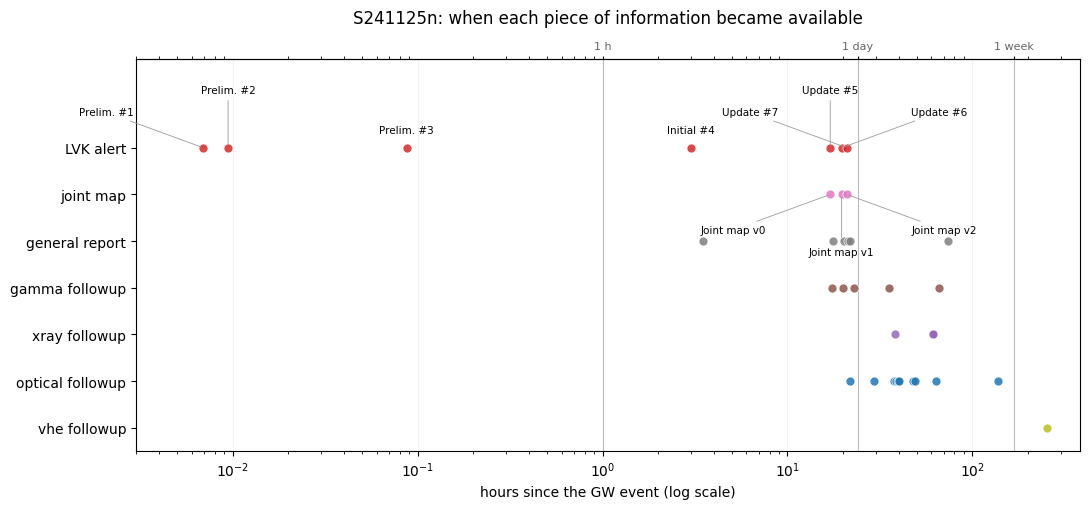

In [4]:
fig, ax = plt.subplots(figsize=(11, 5.2)); plots.timeline(log, ax=ax); fig.tight_layout(); fig.savefig(FIG / "01_timeline.png", dpi=130); plt.show()

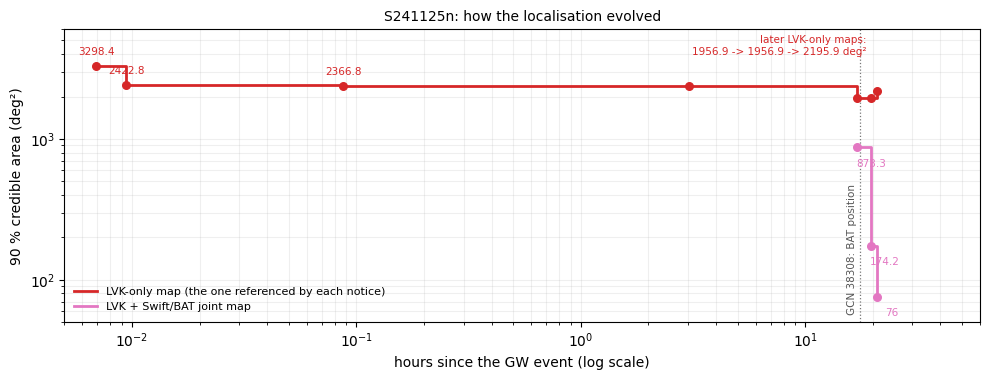

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.9))
ps.localisation_evolution(log, ax=ax, notes=[(H("2024-11-25 18:29:13"), "GCN 38308: BAT position")])
fig.tight_layout(); fig.savefig(FIG / "02_localisation.png", dpi=130); plt.show()

The LVK-only localisation **never improves** (3298 → 2423 → 2367 → 1957 → 2196 deg²). Only the external coincidence shrinks it, and it does
so in three steps within four hours. The platform's `map_areas` field kept showing the LVK-only numbers (1957, 1957, 2196 deg²) for notices #5–#7; the joint
maps are a separate product in the notice.

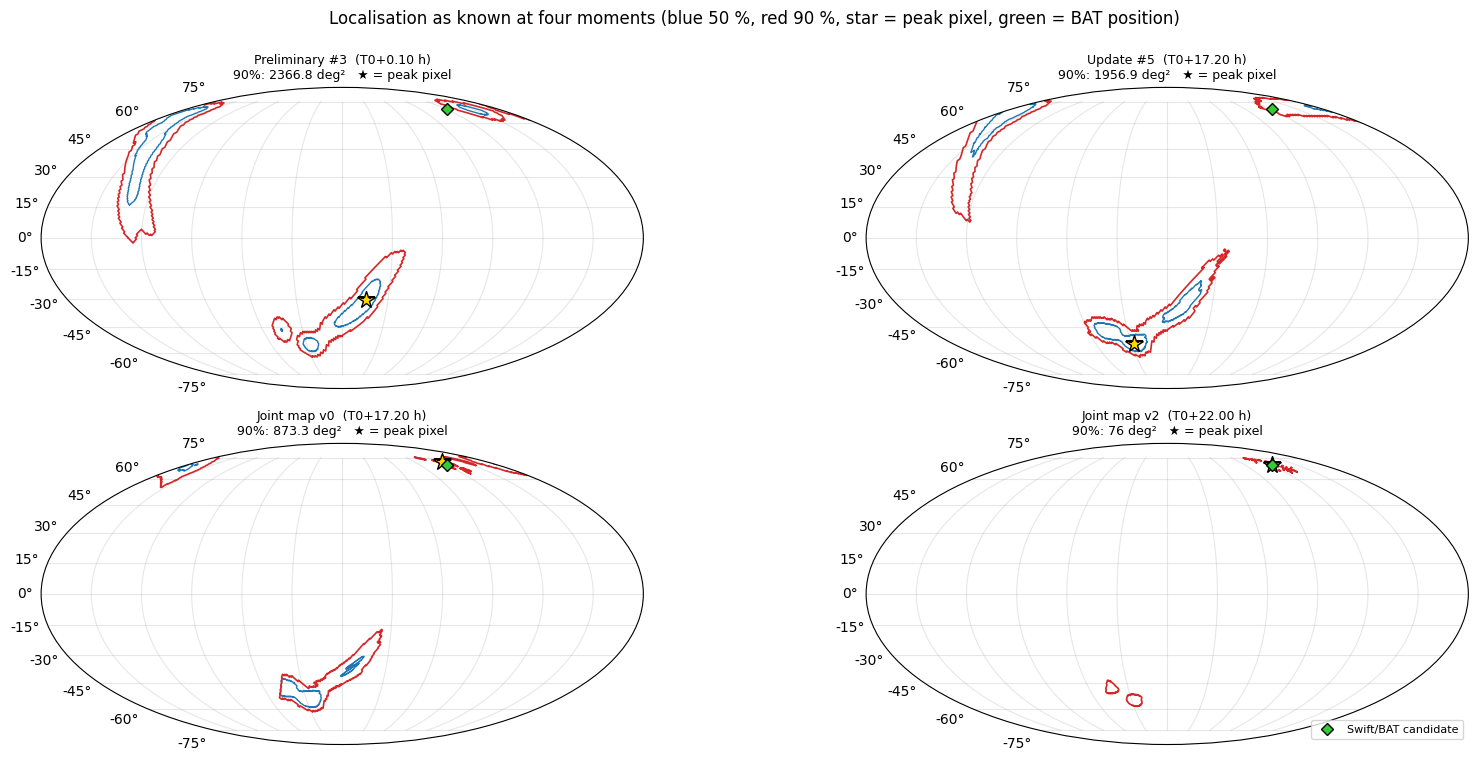

In [6]:
fig = plt.figure(figsize=(17, 7.6))
for i, (h, kind) in enumerate([(0.1, "alert"), (17.2, "alert"), (17.2, "joint"), (22.0, "joint")]):
    ax = fig.add_subplot(2, 2, i + 1, projection="mollweide")
    plots.skymap(log, t_after(log, hours=h), ax=ax, kind=kind, marks=[(E.BAT[0], E.BAT[1], "Swift/BAT candidate")])
ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Localisation as known at four moments (blue 50 %, red 90 %, star = peak pixel, green = BAT position)", y=.995)
fig.tight_layout(); fig.savefig(FIG / "03_skymaps.png", dpi=110, bbox_inches="tight"); plt.show()

### How significant was the association, as known at the time?

The numbers an observer could read changed a lot in three days. Rates are the *joint false-alarm rate* of the coincidence, i.e. how often a
chance coincidence this good would occur. It is **not** a probability that the burst is the counterpart.

In [7]:
SEC = 365.25 * 86400
j0 = [r for r in joints][0]["data"]; j2 = [r for r in joints][-1]["data"]
tab = pd.DataFrame([
    ("T+17.04 h", "notice #5 (machine-readable)", j0["joint_far_hz"], "time + sky"),
    ("T+17.63 h", "GCN 38309", 1.2e-10, "time + sky (restated)"),
    ("T+21.89 h", "GCN 38315, joint map v2", 1.8e-11, "time + sky"),
    ("T+73.42 h", "GCN 38356: 'update on the method'", 1 / (6 * SEC), "untargeted, conservative BBH rate (1 per 3 days)"),
], columns=["when", "source", "joint FAR (Hz)", "method"])
tab["one false alarm per (yr)"] = (1 / (tab["joint FAR (Hz)"] * SEC)).round(1)
tab

,when,source,joint FAR (Hz),method,one false alarm per (yr)
0,T+17.04 h,notice #5 (machine-readable),1.241899e-10,time + sky,255.2
1,T+17.63 h,GCN 38309,1.200000e-10,time + sky (restated),264.1
2,T+21.89 h,"GCN 38315, joint map v2",1.800000e-11,time + sky,1760.4
3,T+73.42 h,GCN 38356: 'update on the method',5.281348e-09,"untargeted, conservative BBH rate (1 per 3 days)",6.0


GCN 38356 explains that the earlier "1 in 10²–10³ yr" figures were *dominated by the low FAR of the confident GW signal* and that,
accounting for the BBH detection rate, the conservative figure is about one per six years. **The people who decided to observe at ~18:30 saw
"one in a hundred years"; the more appropriate number, published three days later, is ~10² times less impressive.** This is exactly the kind of
information that a replay needs to expose.

## 4. When could one observe? (geometry, dark time, real start)

Dark time follows tilepy's convention for IACTs: Sun below −18° and Moon below −0.5°. Zenith angle ≤ 60°.

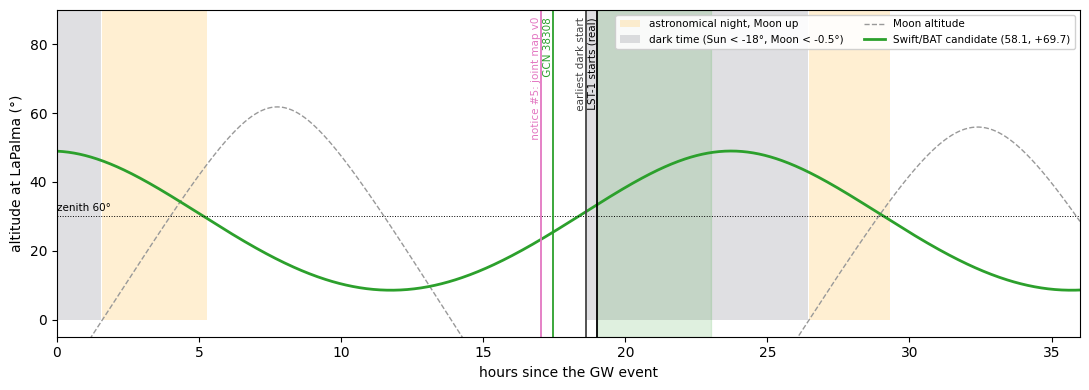

In [8]:
marks = [(H("2024-11-25 18:03:24"), "notice #5: joint map v0", "#e377c2"), (H("2024-11-25 18:29:13"), "GCN 38308", "#2ca02c"),
         (H("2024-11-25 19:37:16"), "earliest dark start", "#444"), (H("2024-11-25 20:01:49"), "LST-1 starts (real)", "#000")]
fig, ax = plt.subplots(figsize=(11, 4))
ps.night_visibility(E.T0, "LaPalma", {"Swift/BAT candidate (58.1, +69.7)": E.BAT}, hours=(0, 36), marks=marks, ax=ax)
ax.axvspan(H("2024-11-25 20:01:49"), H("2024-11-25 20:01:49") + 4, color="#2ca02c", alpha=.15)
fig.tight_layout(); fig.savefig(FIG / "04_visibility.png", dpi=130); plt.show()

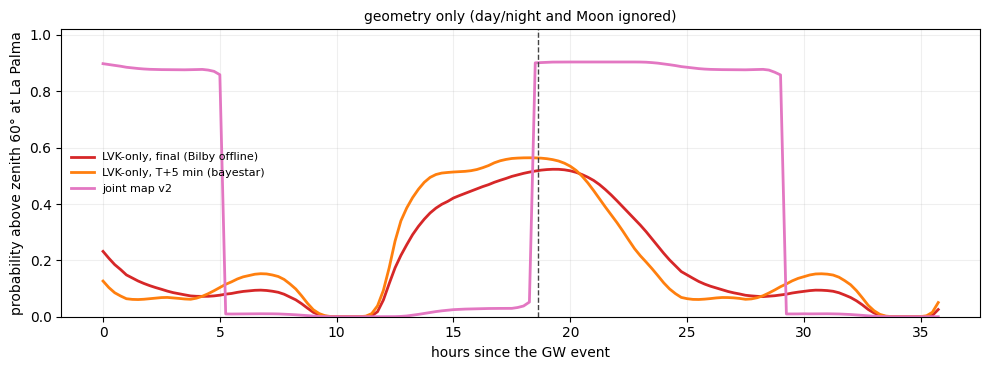

max probability La Palma can ever reach in the LVK-only maps: {'T+5 min': np.float64(0.56), 'final': np.float64(0.52)}


In [9]:
fig, ax = plt.subplots(figsize=(10, 3.8))
SK = study.ROOT / E.SK
for name, f, col in [("LVK-only, final (Bilby offline)", "bilby_offline0_0", "#d62728"), ("LVK-only, T+5 min (bayestar)", "bayestar_2", "#ff7f0e"), ("joint map v2", "combined_2", "#e377c2")]:
    h, v = ps.visible_probability(SK / f"{f}.fits.gz", "LaPalma", E.T0, (0, 36), step_h=.25)
    ax.plot(h, v, color=col, lw=2, label=name)
ax.axvline(H("2024-11-25 19:37:16"), color="#444", ls="--", lw=1)
ax.set_xlabel("hours since the GW event"); ax.set_ylabel("probability above zenith 60° at La Palma"); ax.set_ylim(0, 1.02); ax.grid(alpha=.2)
ax.legend(fontsize=8, frameon=False, loc="center left"); ax.set_title("geometry only (day/night and Moon ignored)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "08_visible_probability.png", dpi=120); plt.show()
print("max probability La Palma can ever reach in the LVK-only maps:",
      {n: round(max(ps.visible_probability(SK / f"{f}.fits.gz", "LaPalma", E.T0, (0, 30), step_h=.5)[1]), 2) for n, f in [("T+5 min", "bayestar_2"), ("final", "bilby_offline0_0")]})

Two facts decide most of what follows: **(i)** La Palma can reach at most about half of any LVK-only map (the southern lobes never rise), and
**(ii)** the BAT position only gets above zenith 60° at about the time dark time begins (~19:37 UTC), so *nothing* could be observed there earlier,
whatever the decision speed.

## 5. Five strategies, replayed

Each strategy is a sequence of *decisions*; at each decision tilepy plans with the information then available. When new information arrives, tiles that
have already started are kept and passed to tilepy as "already observed"; the rest is re-planned; the telescope is never double-booked.
Defaults: La Palma, circular field of view of **radius 2.5°** (5° diameter), 20-min tiles, zenith ≤ 60°, dark time, ≤ 2 nights, no reaction delay.

| | decisions (UTC, from the information timeline) | information used |
|---|---|---|
| **A** act at once | 01:01:50, 01:06:30, then 18:03:24, 21:58:12 | LVK-only maps as they arrive |
| **B** wait for PE map | 18:03:24, 21:58:12 | LVK-only Bilby maps |
| **C** point at the BAT candidate | 18:29:14 (GCN 38308, created 18:29:13.486) | the 5′ position — *what MAGIC+LST-1 did* |
| **D** tile the joint map | 18:03:24, 20:38:34, 21:58:12 | joint maps v0, v1, v2 |
| **E** hybrid | 01:01:50, 01:06:30, 18:29:14, 20:38:34, 21:58:12 | LVK-only at night, then BAT, then joint maps |

Scoring is against two **hypotheses** about where the source is, used for evaluation only:
**H1** = the Swift/BAT burst *is* the counterpart (final joint map); **H0** = unrelated (final LVK-only map).
The probability *p* that H1 is true is unknown, so results are shown for both and as a function of *p*.

In [10]:
res = study.run_study(E.EVENT, E.STRATEGIES, list(E.SENSITIVITY.values()), workers=4)
tag = E.BASE.tag()
summ = study.summarise(res, tag, E.STRATEGIES, E.TRUTHS, E.BASE, E.T0)
show = summ[["decision_h", "first_tile_h", "wait_after_decision_h", "n_tiles",
             "cov_H1_first1", "cov_H1_first6", "cov_H1_first12", "cov_H1", "cov_H0_first1", "cov_H0_first6", "cov_H0_first12", "cov_H0"]]
show.columns = ["decision (h)", "first tile (h)", "wait after decision (h)", "tiles",
                "H1 @1 tile", "H1 @6", "H1 @12", "H1 total", "H0 @1 tile", "H0 @6", "H0 @12", "H0 total"]
show

,decision (h),first tile (h),wait after decision (h),tiles,H1 @1 tile,H1 @6,H1 @12,H1 total,H0 @1 tile,H0 @6,H0 @12,H0 total
strategy,,,,,,,,,,,,
A,0.01,0.01,0.00,33,0.0040,0.0085,0.0148,0.0259,0.0240,0.0794,0.1675,0.3474
B,17.04,18.60,1.56,28,0.0036,0.0103,0.0161,0.8850,0.0247,0.1081,0.1808,0.3179
C,17.47,18.60,1.13,1,0.8511,0.8511,0.8511,0.8511,0.0052,0.0052,0.0052,0.0052
D,17.04,18.60,1.56,5,0.0043,0.8817,0.8817,0.8817,0.0226,0.0713,0.0713,0.0713
E,0.01,0.01,0.00,7,0.0040,0.8573,0.8778,0.8778,0.0240,0.0623,0.0676,0.0676


`@n` is the probability covered after the first *n* tiles in time order (n × 20 min of telescope time); *total* is what the strategy covers over
two nights. **Compare strategies at equal budgets**: "total" mostly rewards spending more time (strategy B reaches 88 % under H1 only with its 28th tile,
a low-probability tile that happens to lie 1.6° from the BAT position).

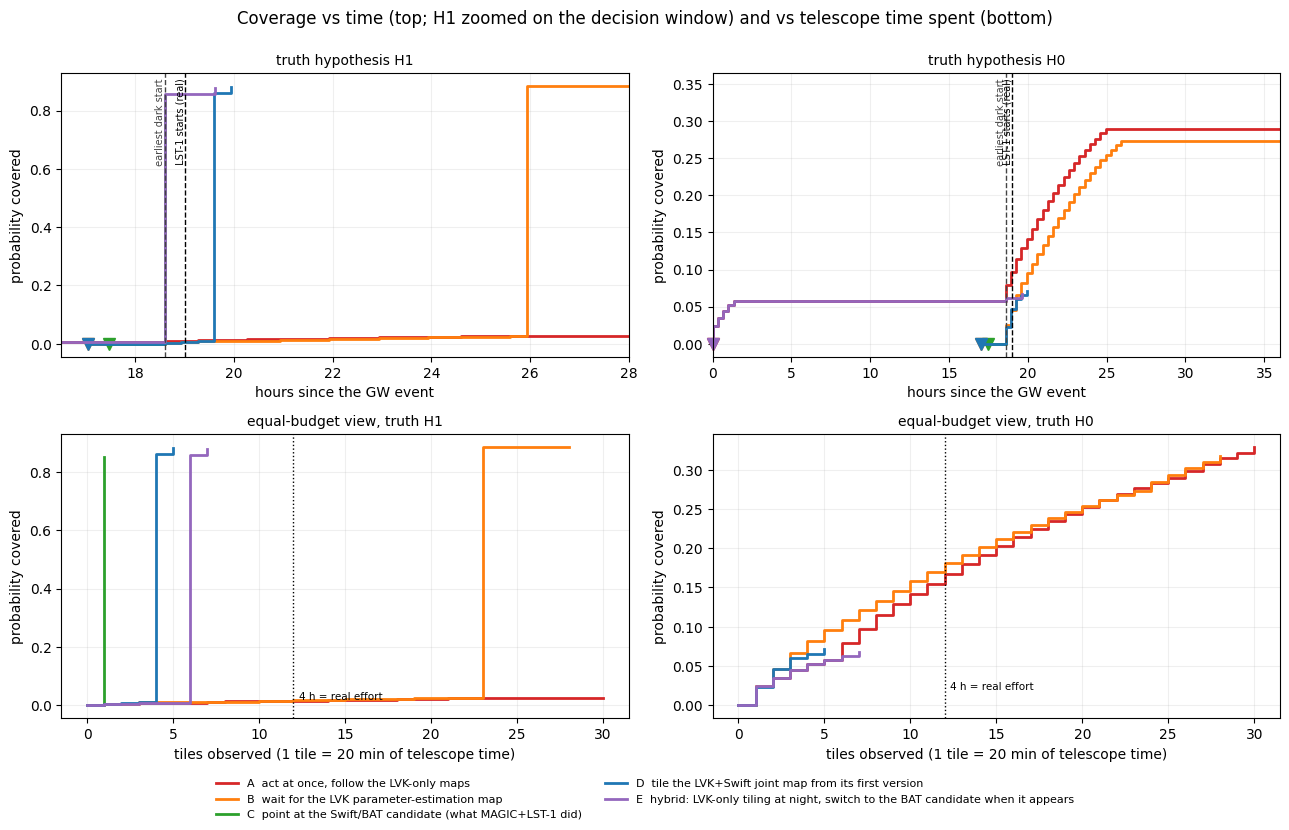

In [11]:
marks = [(H("2024-11-25 19:37:16"), "earliest dark start", "#444"), (H("2024-11-25 20:01:49"), "LST-1 starts (real)", "#000")]
fig, axes = plt.subplots(2, 2, figsize=(13, 8.2))
ps.coverage_vs_time(res, tag, E.STRATEGIES, E.TRUTHS, E.BASE, E.T0, ax_pair=axes[0], xlims={"H1": (16.5, 28), "H0": (0, 36)}, marks=marks)
ps.coverage_vs_tiles(res, tag, E.STRATEGIES, E.TRUTHS, E.BASE, ax_pair=axes[1], nmax=30)
for ax in axes[1]:
    ax.axvline(12, color="k", ls=":", lw=1); ax.text(12.3, .02, "4 h = real effort", fontsize=7.5)
h, l = axes[0][0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=2, fontsize=8, frameon=False)
fig.suptitle("Coverage vs time (top; H1 zoomed on the decision window) and vs telescope time spent (bottom)", y=.995)
fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(FIG / "05_strategies.png", dpi=120); plt.show()

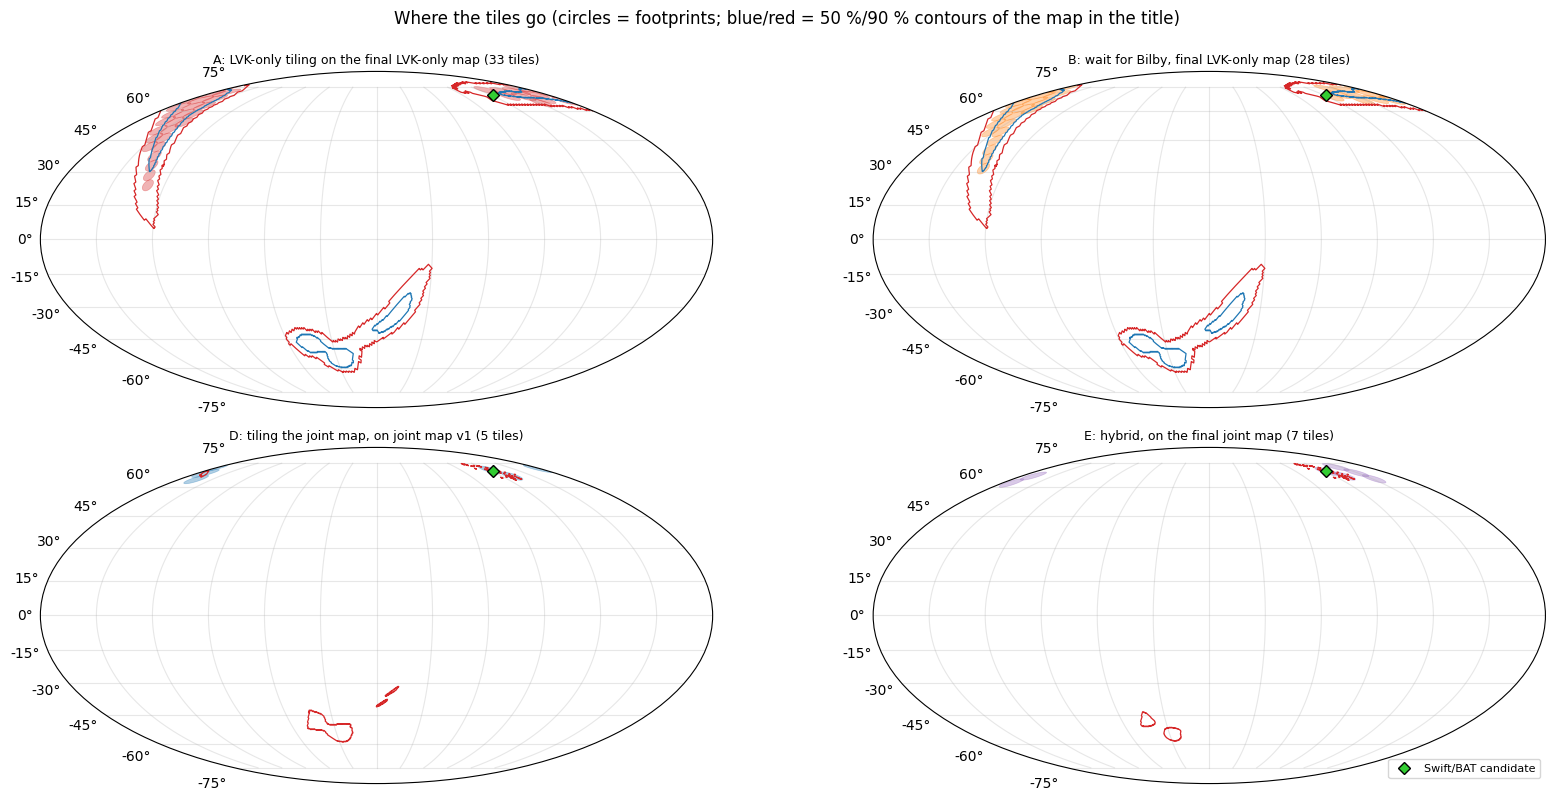

In [12]:
fig = plt.figure(figsize=(17, 8))
cfg = [("A", "bilby_offline0_0", "A: LVK-only tiling on the final LVK-only map"), ("B", "bilby_offline0_0", "B: wait for Bilby, final LVK-only map"),
       ("D", "combined_1", "D: tiling the joint map, on joint map v1"), ("E", "combined_2", "E: hybrid, on the final joint map")]
for i, (k, m, title) in enumerate(cfg):
    ax = fig.add_subplot(2, 2, i + 1, projection="mollweide")
    ps.tiles_on_sky(res[(tag, k)], SK / f"{m}.fits.gz", E.BASE.fov_radius, ax=ax, color=ps.COLORS[k], title=f"{title} ({len(res[(tag, k)])} tiles)",
                    marks=[(E.BAT[0], E.BAT[1], "Swift/BAT candidate")])
ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Where the tiles go (circles = footprints; blue/red = 50 %/90 % contours of the map in the title)", y=.995)
fig.tight_layout(); fig.savefig(FIG / "07_tiles_on_sky.png", dpi=100, bbox_inches="tight"); plt.show()

### Which strategy is better? It depends on *p*, and on the budget

Expected coverage `E(p) = p·cov(H1) + (1−p)·cov(H0)`. The table gives the value of *p* above which strategy X beats the LVK-only strategy at the same budget.

tile on which each strategy first covers > 50 % of H1 (the BAT position): {'C': 1, 'D': 4, 'E': 6}


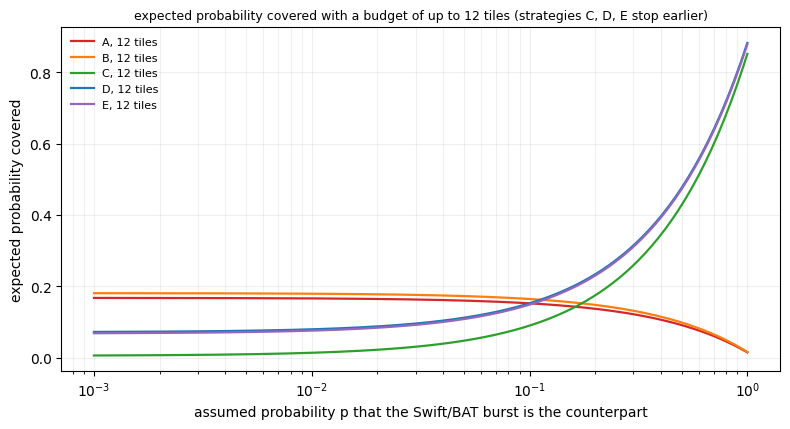

,C beats A,C beats B,D beats A,D beats B,E beats A,E beats B
1 tiles (20 min),0.022,0.022,not yet,not yet,not yet,not yet
3 tiles (60 min),0.045,0.067,not yet,not yet,not yet,not yet
6 tiles (120 min),0.081,0.109,0.009,0.041,0.02,0.051
12 tiles (240 min),0.163,0.174,0.1,0.112,0.104,0.116


In [13]:
def pstar(x, y, n):
    """p above which x beats y at budget n; 'not yet' while x has not reached the BAT position (differences are noise)."""
    c1x, c0x = summ.loc[x, f"cov_H1_first{n}"], summ.loc[x, f"cov_H0_first{n}"]
    c1y, c0y = summ.loc[y, f"cov_H1_first{n}"], summ.loc[y, f"cov_H0_first{n}"]
    if c1x < 0.5:
        return "not yet"
    return round((c0y - c0x) / ((c1x - c1y) + (c0y - c0x)), 3)
tabp = pd.DataFrame({f"{x} beats {y}": {f"{n} tiles ({20 * n} min)": pstar(x, y, n) for n in (1, 3, 6, 12)}
                     for x in "CDE" for y in "AB"})
_cov = {k: study.Scorer(study.ROOT / E.TRUTHS["H1"], E.BASE.fov_radius).cumulative(res[(tag, k)]).coverage.values for k in "CDE"}
tile_reached = {k: (int(np.argmax(c > 0.5)) + 1 if (c > 0.5).any() else None) for k, c in _cov.items()}
print("tile on which each strategy first covers > 50 % of H1 (the BAT position):", tile_reached)
fig, ax = plt.subplots(figsize=(8, 4.4))
ps.expected_coverage(summ, E.STRATEGIES, budgets=(12,), ax=ax); ax.legend(fontsize=8, frameon=False)
ax.set_title("expected probability covered with a budget of up to 12 tiles (strategies C, D, E stop earlier)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "06_expected.png", dpi=120); plt.show()
tabp

Reading the table: a strategy that uses the BAT candidate beats LVK-only tiling once *p* exceeds the value shown. Strategy C already reaches the BAT position with its first tile, so
it wins at a one-tile budget for a *p* of a few percent; D and E only reach it after 4 and 6 tiles (the first joint map is still multi-modal) and then need *p* above ≈ 1–5 %
at 2 h and ≈ 10–12 % at 4 h; C needs ≈ 16–17 % at a 4 h budget because the LVK-only strategies, given 12 tiles, collect a lot of H0 probability that C does not spend time on.
The decision hinges on a number (*p*) that the joint FAR does not give, and that LVK itself later said had been overstated.

## 6. The replay versus what really happened

In [14]:
import astropy.units as u
from astropy.coordinates import SkyCoord, AltAz, EarthLocation
from astropy.time import Time
c = res[(tag, "C")]
first = c.time.min()
real = pd.Timestamp(E.REAL["lst1_start"])
loc = EarthLocation(lat=28.76 * u.deg, lon=-17.89 * u.deg, height=2200 * u.m)
def zen(t): return 90 - SkyCoord(*E.BAT, unit="deg").transform_to(AltAz(obstime=Time(pd.Timestamp(t).to_pydatetime()), location=loc)).alt.deg
ladder = pd.DataFrame([
    ("notice #5 with the joint map (machine-readable)", "2024-11-25 18:03:24", "-"),
    ("GCN 38308: BAT position published", "2024-11-25 18:29:13", "-"),
    ("earliest start allowed (tilepy: dark time, zenith <= 60 deg)", str(first), f"zenith {zen(first):.0f} deg"),
    ("MAGIC+LST-1 start (real)", str(real), f"zenith {zen(real):.0f} deg (paper: 55 deg)"),
], columns=["event", "UTC", "note"])
ladder["minutes after GCN 38308"] = [(pd.Timestamp(t) - pd.Timestamp("2024-11-25 18:29:13")).total_seconds() / 60 for t in ladder["UTC"]]
print(f"zenith at the end of the real run (+4 h): {zen(real + pd.Timedelta(hours=4)):.0f} deg (paper: 40 deg)")
ladder.round(1)

zenith at the end of the real run (+4 h): 41 deg (paper: 40 deg)


,event,UTC,note,minutes after GCN 38308
0,notice #5 with the joint map (machine-readable),2024-11-25 18:03:24,-,-25.8
1,GCN 38308: BAT position published,2024-11-25 18:29:13,-,0.0
2,"earliest start allowed (tilepy: dark time, zen...",2024-11-25 19:37:16,zenith 59 deg,68.0
3,MAGIC+LST-1 start (real),2024-11-25 20:01:49,zenith 57 deg (paper: 55 deg),92.6


**The decision was not the bottleneck.** The BAT position was public at 18:29; the earliest moment the sky allowed an observation was ~19:37; the real
team started at 20:01:49, **~25 min after the earliest possible start**. A faster decision could not have helped, a slower one (up to ~70 min) would not
have mattered. This is a statement about the *plan*; it says nothing about the data quality, which was ruined by clouds
(LIDAR transmission 0.8 → 0.4; only 19.7 min of joint data survived quality cuts out of 201.6 min).

Our zenith angles are up to 2° above the paper's (57° vs 55° at the start, 41° vs 40° at the end), which we attribute to the site coordinates and the exact start time used.

### What the team could read at the moment it started observing

In [15]:
print(format_snapshot(state_at(log, E.REAL["lst1_start"])))

=== S241125n @ 2024-11-25T20:01:49  (T0 + 19.01 h) ===
Latest LVK alert: Update #5 (available 2024-11-25T18:03:24)  [SIGNIFICANT alert]
  localisation: 50%=526.4 deg2  90%=1956.9 deg2  lobes(90%): (185,-42), (147,-10), (328,+53)
  peak-probability pixel (not the localisation!): RA=207.6 Dec=-54.7
  distance ~4474 Mpc  FAR=0.03 per year
  class: Terrestrial=0% BNS=0% NSBH=0% BBH=100%;  P(has NS | astrophysical)=0.0
  comment: (none)
Alerts so far: 5 -> Preliminary #1, Preliminary #2, Preliminary #3, Initial #4, Update #5
External coincidence (Swift SubGRBTargeted), Joint map v0 (available 2024-11-25T18:03:24):
  joint map 50%=208.014 deg2  90%=873.3 deg2, peak RA=55.9 Dec=+71.7
  GRB candidate 0.25 s after the GW; coincidence FAR: time only 1.5e-10 Hz, time+sky 1.2e-10 Hz (as stated in the notice)
GCN circulars so far: 3  {'general_report': 2, 'gamma_followup': 1}
  2024-11-25T04:30:37  GCN 38305  LVK              LIGO/Virgo/KAGRA S241125n: Identification of a GW compact binary merge
  

When LST-1 started (T+19.01 h) exactly **three circulars** existed (the LVK identification, the BAT-GUANO candidate and the LVK update with the coincidence),
five LVK notices and the first joint map. *Every* other follow-up result arrived later: INTEGRAL, Fermi-GBM and Konus-Wind upper limits (T+20–35 h), the first optical
limits (Kinder observed from T+17.9 h but published at T+21.7 h; COLIBRI circular at T+29.3 h; HCT circular at T+37.5 h) and the X-ray sources inside the BAT error circle (T+38 h onward). The IACT observation was therefore
a genuine "first look" at the candidate position, not a follow-up of a refined X-ray counterpart. INTEGRAL's limit is weak anyway: the BAT position was 25° from its pointing axis (GCN 38311).

In [16]:
# what fraction of the final joint map one pointing at BAT covers, for the real instruments' fields of view
for name, r in [("LST-1 (4.3 deg diameter)", 2.15), ("MAGIC (3.5 deg diameter)", 1.75), ("our default (5 deg diameter)", 2.5)]:
    print(f"{name:30s} P(H1) in one field centred on BAT = {sm.prob_in_disc(pj, nj, *E.BAT, r):.3f}")

LST-1 (4.3 deg diameter)       P(H1) in one field centred on BAT = 0.851
MAGIC (3.5 deg diameter)       P(H1) in one field centred on BAT = 0.850
our default (5 deg diameter)   P(H1) in one field centred on BAT = 0.851


## 7. Sensitivity (one change at a time)

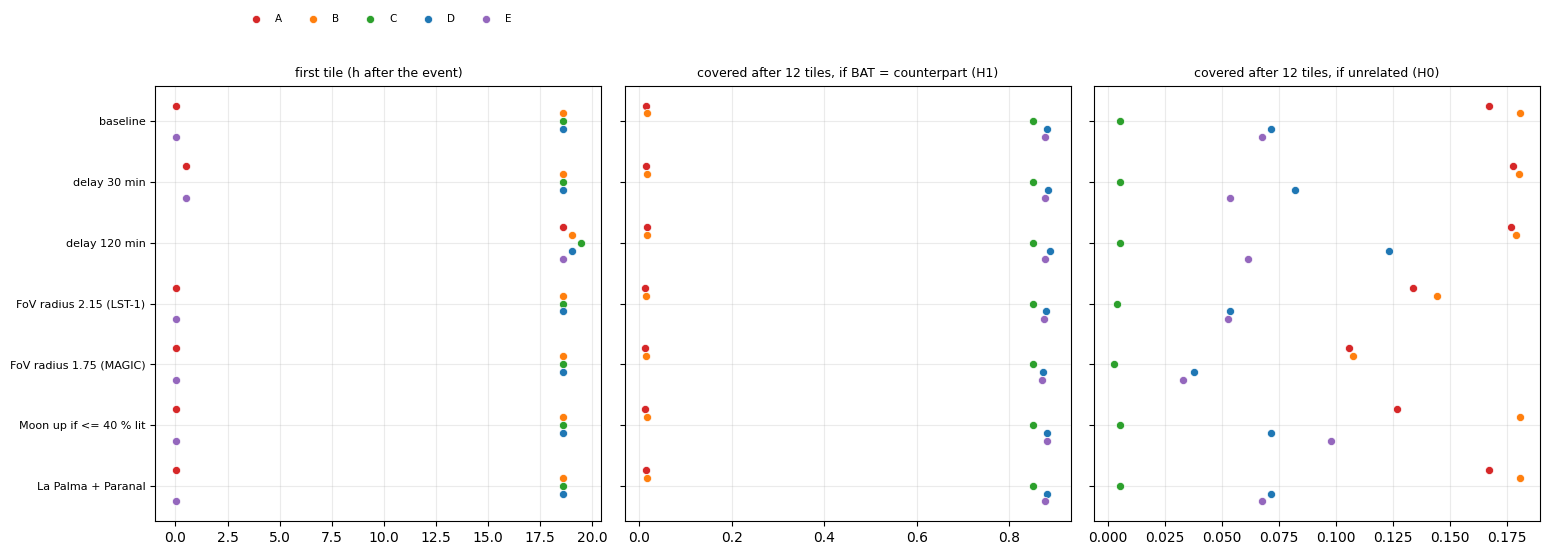

In [17]:
frames = {n: study.summarise(res, su.tag(), E.STRATEGIES, E.TRUTHS, su, E.T0) for n, su in E.SENSITIVITY.items()}
fig = ps.sensitivity_figure(frames, E.STRATEGIES); fig.savefig(FIG / "09_sensitivity.png", dpi=120); plt.show()

In [18]:
big = pd.concat({n: f[["first_tile_h", "cov_H1_first12", "cov_H0_first12"]] for n, f in frames.items()}, names=["setup", "strategy"])
big.round(3).unstack("strategy")

first_tile_h                             cov_H1_first12                             cov_H0_first12                            
strategy                           A      B      C      D      E              A      B      C      D      E              A      B      C      D      E
setup                                                                                                                                                 
baseline                        0.01  18.60  18.60  18.60   0.01          0.015  0.016  0.851  0.882  0.878          0.168  0.181  0.005  0.071  0.068
delay 30 min                    0.51  18.60  18.60  18.60   0.51          0.015  0.016  0.851  0.884  0.876          0.178  0.181  0.005  0.082  0.054
delay 120 min                  18.60  19.04  19.47  19.04  18.60          0.017  0.017  0.851  0.889  0.876          0.177  0.179  0.005  0.124  0.061
FoV radius 2.15 (LST-1)         0.01  18.60  18.60  18.60   0.01          0.012  0.014  0.851  0.879  0.875          0.134  0.145  0.004  0.054  0.053
FoV radius 1.75 (MAGIC)         0.01  18.60  18.60  18.60   0.01          0.012  0.014  0.850  0.873  0.871          0.106  0.108  0.003  0.038  0.033
Moon up if <= 40 % lit          0.01  18.60  18.60  18.60   0.01          0.013  0.016  0.851  0.882  0.881          0.127  0.181  0.005  0.071  0.098
La Palma + Paranal              0.01  18.60  18.60  18.60   0.01          0.015  0.016  0.851  0.882  0.878          0.168  0.181  0.005  0.071  0.068

What does *not* change: the ordering of the strategies, the ~85–89 % coverage of H1 by C/D/E, the ~1–2 % by A/B, and the first tile of B/C/D at the start of
dark time. What does: the night-1 tiles of A and E exist only if the response is quicker than ~1.5 h (the Moon rises at ~T+1.4 h; with a 120-min delay A has
no tile in night 1); smaller fields of view cut A/B's H0 coverage (0.18 → 0.11); allowing observation with the Moon up (≤ 40 % lit) lets E reach the BAT position later in its tile sequence.
Adding Paranal changes nothing within 12 tiles: the BAT position never rises there, and the southern lobes of the LVK maps come up only after the first night.

## 8. Quiz mode

*It is 18:13 UTC. You are the on-call observer for a telescope on La Palma. Decide, then reveal.*

In [19]:
q = Quiz(log)
q.ask(hours=17.2)

=== S241125n @ 2024-11-25T18:13:16  (T0 + 17.20 h) ===
Latest LVK alert: Update #5 (available 2024-11-25T18:03:24)  [SIGNIFICANT alert]
  localisation: 50%=526.4 deg2  90%=1956.9 deg2  lobes(90%): (185,-42), (147,-10), (328,+53)
  peak-probability pixel (not the localisation!): RA=207.6 Dec=-54.7
  distance ~4474 Mpc  FAR=0.03 per year
  class: Terrestrial=0% BNS=0% NSBH=0% BBH=100%;  P(has NS | astrophysical)=0.0
  comment: (none)
Alerts so far: 5 -> Preliminary #1, Preliminary #2, Preliminary #3, Initial #4, Update #5
External coincidence (Swift SubGRBTargeted), Joint map v0 (available 2024-11-25T18:03:24):
  joint map 50%=208.014 deg2  90%=873.3 deg2, peak RA=55.9 Dec=+71.7
  GRB candidate 0.25 s after the GW; coincidence FAR: time only 1.5e-10 Hz, time+sky 1.2e-10 Hz (as stated in the notice)
GCN circulars so far: 1  {'general_report': 1}
  2024-11-25T04:30:37  GCN 38305  LVK              LIGO/Virgo/KAGRA S241125n: Identification of a GW compact binary merge

--- Your turn ---
1. W

In [20]:
q.reveal(hours=17.2, window_hours=6)    # run only after you have decided

=== Reveal: what arrived in the next 6 h (T0 + 17.20 h -> +6 h) ===
  T0+  17.47 h  Swift/BAT-GUANO GCN 38308    LIGO/Virgo/KAGRA S241125n: Swift/BAT-GUANO candidate counterpart
  T0+  17.63 h  LVK          GCN 38309    LIGO/Virgo/KAGRA S241125n: Updated Sky localization and Coincidence with Exter
  T0+  19.62 h  LVK          Update #6    Update #6: 90% area 1956.9 deg2
  T0+  19.62 h  LVK+Swift    Joint map v1 Joint map v1: 90% area 174.2 deg2
  T0+  20.09 h  INTEGRAL     GCN 38311    LIGO/Virgo/KAGRA S241125n: No counterpart candidates in INTEGRAL SPI-ACS promp
  T0+  20.09 h  LVK          GCN 38312    LIGO/Virgo/KAGRA S241125n: Updated Coincidence with External Event
  T0+  20.95 h  LVK          Update #7    Update #7: 90% area 2195.9 deg2
  T0+  20.95 h  LVK+Swift    Joint map v2 Joint map v2: 90% area 76 deg2
  T0+  21.14 h  LVK          GCN 38313    LIGO/Virgo/KAGRA S241125n: Updated Sky localization
  T0+  21.73 h  Kinder       GCN 38314    LIGO/Virgo/KAGRA S241125n: Kinder opti

## 9. Summary of findings

In [21]:
c1, c0 = summ.loc["C", "cov_H1"], summ.loc["C", "cov_H0"]
print(f"1. LVK-only localisation never improved: {alerts[0]['data']['area90']:.0f} -> {alerts[-1]['data']['area90']:.0f} deg2 over {H(alerts[-1]['t']):.1f} h; "
      f"only the external coincidence shrank it ({joints[0]['data']['area90']:.0f} -> {joints[-1]['data']['area90']:.0f} deg2).")
print(f"2. Pointing at the BAT position (C) covers {c1:.0%} of the final joint map with ONE 20-min tile, but only {c0:.1%} of the LVK-only map.")
print(f"3. At 12 tiles (4 h), LVK-only tiling (A/B) covers {summ.loc['A','cov_H0_first12']:.0%}-{summ.loc['B','cov_H0_first12']:.0%} of the LVK-only map and {summ.loc['A','cov_H1_first12']:.1%}-{summ.loc['B','cov_H1_first12']:.1%} of the joint map.")
print(f"4. The joint-map strategies (D, E) reach {summ.loc['D','cov_H1']:.0%}/{summ.loc['E','cov_H1']:.0%} of H1 within {summ.loc['D','n_tiles']:.0f}/{summ.loc['E','n_tiles']:.0f} tiles; D needs "
      f"{summ.loc['D','t10_H1_h'] - summ.loc['C','t10_H1_h']:.1f} h more than C because the first joint map (873 deg2) is still multi-modal.")
print(f"5. The real start (20:01:49) was {(real - first).total_seconds() / 60:.0f} min after the earliest possible one; the decision was not the bottleneck.")
print("6. The association was reported as 'one in ~10^2-10^3 yr'; three days later LVK gave 'one in ~6 yr'.")

1. LVK-only localisation never improved: 3298 -> 2196 deg2 over 20.9 h; only the external coincidence shrank it (873 -> 76 deg2).
2. Pointing at the BAT position (C) covers 85% of the final joint map with ONE 20-min tile, but only 0.5% of the LVK-only map.
3. At 12 tiles (4 h), LVK-only tiling (A/B) covers 17%-18% of the LVK-only map and 1.5%-1.6% of the joint map.
4. The joint-map strategies (D, E) reach 88%/88% of H1 within 5/7 tiles; D needs 1.0 h more than C because the first joint map (873 deg2) is still multi-modal.
5. The real start (20:01:49) was 25 min after the earliest possible one; the decision was not the bottleneck.
6. The association was reported as 'one in ~10^2-10^3 yr'; three days later LVK gave 'one in ~6 yr'.


## Known limitations

**Information and knowledge time**
* The log contains the LVK notices, the sky maps and the GCN circulars. It does **not** contain other real-time channels (the Swift/GUANO notice itself,
  private communications, Slack/e-mail, ATels). The Swift GUANO notice (id 754189311) was referenced by LVK notice #5 at 18:03:24, so the *machine-readable* coincidence
  was available at least from then; when the real team learned it is not stated in the paper. Strategy C uses the human-readable GCN 38308 (created 18:29:13.486, used as 18:29:14), which is conservative.
* Circular times are NASA's `createdOn` rounded up to the next second (never earlier than reality); readers saw them when they read them. LVK notice times are distribution times; the platform lagged by 14–22 s.
* Maps that existed on GraceDB earlier than their notice (e.g. Bilby at 07:06) are excluded from the replay. This does not change strategy B, because La Palma is in daylight
  between ~07:30 and ~18:15 UTC and the plan is made at nightfall either way.
* The *joint FAR* in the three joint-map notices is 1.2×10⁻¹⁰ Hz, while GCN 38315 quotes 1.8×10⁻¹¹ Hz for the last map; the notice and the circular disagree and we report both.
* Only three events have been processed with this machinery (S250818k, S241125n, S250206dm), all gravitational-wave alerts; nothing here is a statistic.

**Hypotheses and scoring**
* **H1/H0 are assumptions.** The joint FAR is *not* a probability of association, and the probability *p* needs a prior on how often BBH mergers have a detectable gamma-ray counterpart (unknown). We show results for both and as a function of *p* but do not pick one.
* "Probability covered" is purely geometric. It ignores sensitivity, energy range, source brightness and whether VHE emission is expected from a BBH at all. The real observation produced upper limits only.
* Scoring uses the *final* maps (evaluation only). The final joint map is itself one model of the localisation, dominated by one BAT candidate.

**Instrument model and scheduling**
* One site (La Palma) and a generic circular field of view of radius 2.5°; LST-1 is 2.15° and MAGIC 1.75°. Real operations use **wobble pointings**, not tiling, for well-localised targets.
* No slew or setup time (the LST-1 slews 180° in ~20 s), no weather: in reality ~90 % of the data was lost to clouds. A reaction delay is explored only up to 2 h.
* tilepy settings are its defaults plus our choices (`minProbcut` 0.5 %, 20-min runs, greedy 2D FoV-integrated strategy, `maxNights` 2). The number of tiles of each strategy is largely set by the 0.5 % cut and the two-night window, so "total coverage" must not be compared across strategies without looking at the budget.
* Dark time is Sun < −18°, Moon < −0.5°, tilepy's convention for IACTs. The "Moon up if ≤ 40 % lit" sensitivity uses tilepy's grey time with the Moon-altitude threshold at the horizon. tilepy's grey time is an OR (Moon below the threshold altitude at any illumination, or above it if under the illumination limit); an earlier version of this study used a 30° threshold and described it as an AND, which was wrong (same numbers here, because the Moon was 32 % lit); LST-1 and MAGIC do observe under moderate moonlight but we found no fixed published limit for LST-1.
* tilepy checks its constraints at the *start* of each run; at the end of a 20-min run the zenith angle can exceed 60° by a few degrees.
* With several sites, each site plans **independently** (no cross-site coordination), so sites can re-observe each other's fields. In the La Palma + Paranal setup of this event there is no overlap (Paranal tiles come only on the next morning), but multi-site numbers are in general a lower bound.
* Sensitivities are one-at-a-time; interactions were not explored.
* **Only the `@n` (first-n-tiles) metrics are budget-fair.** Each re-plan restarts tilepy's two-night / 20-runs-per-night horizon from that decision, so strategies with late decisions get a longer window and more tiles; "total" coverage is not an equal-budget comparison. A strategy with fewer than n tiles has `@n` equal to its total (it simply spends less time).

**Replay engine**
* Contour polygons come from `ligo.skymap` at nside 256; areas of very small credible regions are computed at nside 1024; maps for planning and scoring are rasterised to nside 512 (probability is conserved, positions are good to ~0.1°).
* The quiz is text only, without scoring.